# Plot a Mork-2 training run

Reads `runs/<run>/metrics.csv` from `mork-train`. The most recently updated run is selected unless `RUN_NAME` is set.

In [6]:
import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

RUNS_DIR = Path("../runs")
RUN_NAME = None  # e.g. "20261018_120000" or "cool_18k"

# Most recently written run last; names like cool_18k don't sort by time.
runs = sorted(
    (p for p in RUNS_DIR.glob("*") if p.is_dir() and (p / "metrics.csv").exists()),
    key=lambda p: (p / "metrics.csv").stat().st_mtime,
)
print("available runs:", [r.name for r in runs] or "(none)")

if RUN_NAME is not None:
    RUN = RUNS_DIR / RUN_NAME
    assert (RUN / "metrics.csv").exists(), f"no metrics.csv in {RUN}"
elif runs:
    RUN = runs[-1]
else:
    RUN = None

train = val = None
if RUN is None:
    print(f"no runs yet under {RUNS_DIR.resolve()} — start one with mork-train")
else:
    print(f"plotting {RUN.name}")
    cfg_path = RUN / "config.json"
    if cfg_path.exists():
        cfg = json.loads(cfg_path.read_text())
        model = cfg.get("model", {})
        train_cfg = cfg.get("train", {})
        print(
            "config:",
            f"L{model.get('n_layer')} D{model.get('n_embd')} V{model.get('vocab_size')}",
            f"seq {train_cfg.get('seq_len')}",
            f"batch {train_cfg.get('batch_size')}",
            f"tokens/step {train_cfg.get('total_batch_size')}",
            f"max_lr {train_cfg.get('max_lr')}",
            f"max_steps {train_cfg.get('max_steps')}",
        )
    df = pd.read_csv(RUN / "metrics.csv")
    train = df.loc[df["split"] == "train"].copy()
    val = df.loc[df["split"] == "val"].copy()

available runs: ['cool_18k', '20261017_190144', 'cool_30k']
plotting cool_30k
config: L12 D768 V16384 seq 512 batch 2 tokens/step 32768 max_lr 0.000167 max_steps 32000


## Loss and learning rate

In [1]:
SMOOTH_STEPS = 100  # window for the averaged train-loss line

if train is None:
    print("nothing to plot yet")
else:
    fig, ax_loss = plt.subplots(figsize=(10, 6))
    ax_loss.plot(
        train["step"], train["loss"], label="train loss", linewidth=0.8, alpha=0.35, color="tab:blue"
    )
    smooth = train["loss"].rolling(SMOOTH_STEPS, min_periods=max(1, SMOOTH_STEPS // 5)).mean()
    ax_loss.plot(
        train["step"], smooth, label=f"train loss ({SMOOTH_STEPS}-step mean)", linewidth=2, color="navy"
    )
    if not val.empty:
        ax_loss.plot(val["step"], val["loss"], label="val loss", linewidth=2, color="tab:orange")
    ax_loss.set_ylabel("loss")
    ax_loss.set_xlabel("step")
    ax_loss.set_title(f"Mork-2 loss and learning rate — {RUN.name}")
    ax_loss.grid(True, alpha=0.3)

    ax_lr = ax_loss.twinx()
    ax_lr.plot(
        train["step"],
        train["lr"],
        label="learning rate",
        color="tab:green",
        linewidth=1.5,
        alpha=0.7,
    )
    ax_lr.set_ylabel("lr")

    lines, labels = ax_loss.get_legend_handles_labels()
    lines2, labels2 = ax_lr.get_legend_handles_labels()
    ax_loss.legend(lines + lines2, labels + labels2, loc="upper right")
    plt.tight_layout()
    plt.show()

    cols = [c for c in ("step", "loss", "lr", "grad_norm", "tokens_per_sec", "dt_ms") if c in train.columns]
    print(train[cols].tail())
    if not val.empty:
        print(val[["step", "loss"]].tail())

NameError: name 'train' is not defined

## Throughput

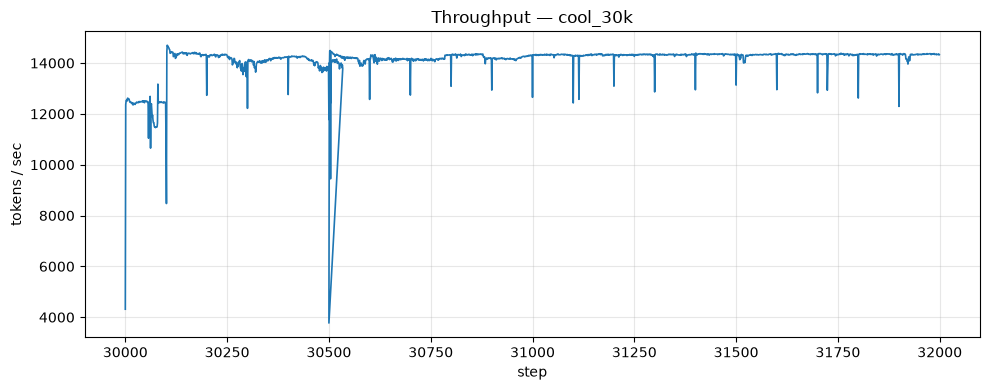

median tokens/sec: 14,312


In [ ]:
if train is None:
    print("nothing to plot yet")
elif "tokens_per_sec" not in train.columns:
    print("no throughput column yet")
else:
    speed = train.dropna(subset=["tokens_per_sec"])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(speed["step"], speed["tokens_per_sec"], linewidth=1.2)
    ax.set(xlabel="step", ylabel="tokens / sec", title=f"Throughput — {RUN.name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"median tokens/sec: {speed['tokens_per_sec'].median():,.0f}")

## Validation improvement

Skips the first few evals, then plots how much validation loss fell since the previous eval.

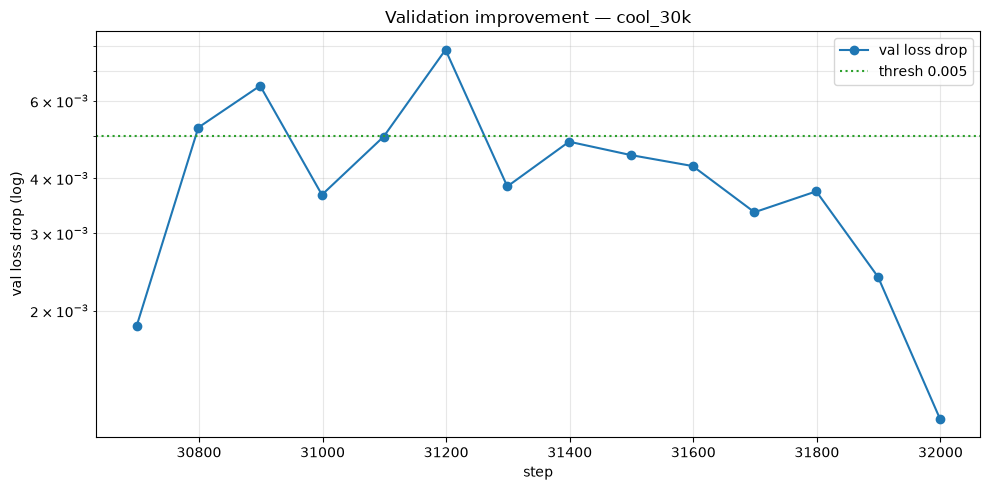

 step     loss  improve
31099 2.432380 0.004976
31199 2.424542 0.007838
31299 2.420710 0.003832
31399 2.415866 0.004844
31499 2.411350 0.004516
31599 2.407086 0.004264
31699 2.403738 0.003348
31799 2.400003 0.003735
31899 2.397617 0.002386
31999 2.396480 0.001137


In [ ]:
SKIP_FIRST = 5
THRESH = 0.005

if val is None or val.empty:
    print("no validation points yet")
else:
    v = val.sort_values("step").assign(improve=lambda d: -d["loss"].diff())
    v = v.dropna(subset=["improve"]).iloc[SKIP_FIRST:]
    falling = v.loc[v["improve"] > 0]

    fig, ax = plt.subplots(figsize=(10, 5))
    if not falling.empty:
        ax.semilogy(falling["step"], falling["improve"], marker="o", label="val loss drop")
    ax.axhline(THRESH, color="tab:green", ls=":", label=f"thresh {THRESH}")
    ax.set(
        xlabel="step",
        ylabel="val loss drop (log)",
        title=f"Validation improvement — {RUN.name}",
    )
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

    if falling.empty:
        print("no positive validation drops in this window")
    else:
        print(falling[["step", "loss", "improve"]].tail(10).to_string(index=False))

## Milestone evals

Reads every `runs/*/loss_eval.csv` and `code_eval.csv`. Hot trunk snapshots are lines; cooled branches (`cool_*`) are markers so the cooldown lift is visible.

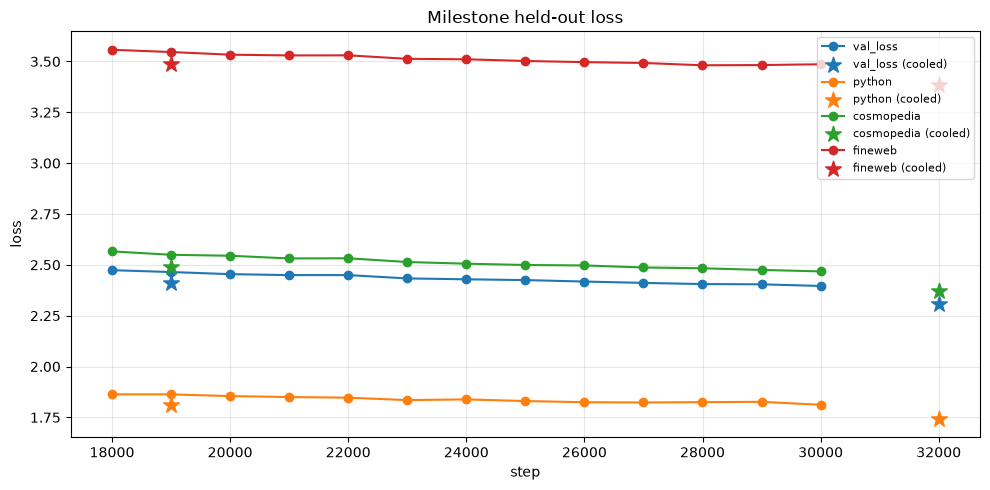

            run  step  val_loss   python  cosmopedia  fineweb
20261017_190144 17999  2.473696 1.863225    2.566173 3.557382
       cool_18k 18999  2.408316 1.811767    2.489322 3.488261
20261017_190144 18999  2.464584 1.863083    2.549377 3.546323
20261017_190144 19999  2.454167 1.854687    2.544696 3.533210
20261017_190144 20999  2.449542 1.849972    2.531493 3.529584
20261017_190144 21999  2.449506 1.846863    2.532198 3.530070
20261017_190144 22999  2.433187 1.834866    2.513822 3.512853
20261017_190144 23999  2.428870 1.838389    2.505599 3.510614
20261017_190144 24999  2.425006 1.830264    2.499187 3.502271
20261017_190144 25999  2.417797 1.824544    2.496925 3.496622
20261017_190144 26999  2.411139 1.823231    2.486942 3.492452
20261017_190144 27999  2.405485 1.824808    2.483111 3.481149
20261017_190144 28999  2.404188 1.826501    2.475001 3.482228
20261017_190144 29999  2.396116 1.811873    2.467696 3.486112
       cool_30k 31999  2.309357 1.744422    2.370129 3.384927


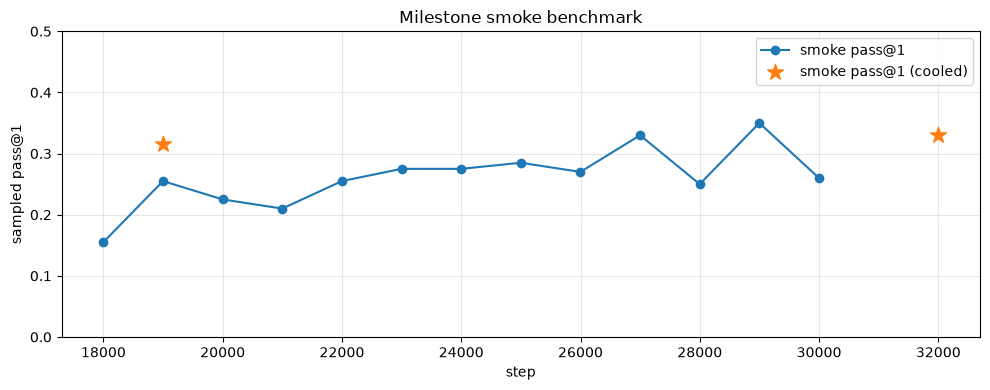

            run  step  greedy_pass  sample_pass_at_1  tasks_solved
       cool_18k 17999            6             0.155            14
       cool_18k 18999           10             0.315            15
20261017_190144 18999            8             0.255            15
20261017_190144 19999            6             0.225            16
20261017_190144 20999            9             0.210            12
20261017_190144 21999           10             0.255            14
20261017_190144 22999           12             0.275            16
20261017_190144 23999           11             0.275            16
20261017_190144 24999           10             0.285            16
20261017_190144 25999           10             0.270            14
20261017_190144 26999           12             0.330            14
20261017_190144 27999           10             0.250            13
20261017_190144 28999           11             0.350            13
20261017_190144 29999            8             0.260          

In [ ]:
LOSS_COLS = ["val_loss", "python", "cosmopedia", "fineweb"]
SMOKE_COL = "sample_pass_at_1"
CODE_SETS = ["smoke", "mid", "smoke-instruct", "mid-instruct"]


def _load_eval_csvs(name: str) -> pd.DataFrame:
    frames = []
    for path in sorted(RUNS_DIR.glob(f"*/{name}")):
        df = pd.read_csv(path)
        if df.empty:
            continue
        df["run"] = path.parent.name
        frames.append(df)
    if not frames:
        return pd.DataFrame()
    out = pd.concat(frames, ignore_index=True)
    out["checkpoint"] = out["checkpoint"].map(lambda p: str(Path(p).expanduser().resolve()))
    # Cool branches live under checkpoints/cool_*/; don't trust the CSV's run folder
    # (an --out path can put a hot snapshot into a cool_* CSV).
    out["cooled"] = out["checkpoint"].map(
        lambda p: any(part.startswith("cool") for part in Path(p).parts)
    )
    # Keep the newest row for each checkpoint (+ task label for code).
    keys = ["checkpoint"] + (["tasks"] if "tasks" in out.columns else [])
    return out.sort_values("time").drop_duplicates(keys, keep="last")


loss_eval = _load_eval_csvs("loss_eval.csv")
code_eval = _load_eval_csvs("code_eval.csv")
if not code_eval.empty:
    code_eval = code_eval.loc[code_eval["tasks"].astype(str).isin(CODE_SETS)].copy()

if loss_eval.empty and code_eval.empty:
    print("no milestone CSVs yet — run mork-eval --tasks loss smoke")
else:
    if not loss_eval.empty:
        fig, ax = plt.subplots(figsize=(10, 5))
        for col in LOSS_COLS:
            if col not in loss_eval.columns:
                continue
            hot = loss_eval.loc[~loss_eval["cooled"]].sort_values("step")
            cool = loss_eval.loc[loss_eval["cooled"]].sort_values("step")
            if not hot.empty:
                ax.plot(hot["step"], hot[col], marker="o", linewidth=1.5, label=col)
            if not cool.empty:
                ax.scatter(
                    cool["step"],
                    cool[col],
                    marker="*",
                    s=140,
                    zorder=5,
                    label=f"{col} (cooled)",
                )
        ax.set(
            xlabel="step",
            ylabel="loss",
            title="Milestone held-out loss",
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8)
        plt.tight_layout()
        plt.show()
        print(loss_eval[["run", "step", *LOSS_COLS]].sort_values("step").to_string(index=False))

    if not code_eval.empty:
        fig, ax = plt.subplots(figsize=(10, 4))
        for i, task_set in enumerate(CODE_SETS):
            rows = code_eval.loc[code_eval["tasks"] == task_set]
            hot = rows.loc[~rows["cooled"]].sort_values("step")
            cool = rows.loc[rows["cooled"]].sort_values("step")
            color = f"C{i}"
            if not hot.empty:
                ax.plot(
                    hot["step"],
                    hot[SMOKE_COL],
                    marker="o",
                    linewidth=1.5,
                    color=color,
                    label=f"{task_set} pass@1",
                )
            if not cool.empty:
                ax.scatter(
                    cool["step"],
                    cool[SMOKE_COL],
                    marker="*",
                    s=140,
                    color=color,
                    edgecolor="black",
                    zorder=5,
                    label=f"{task_set} pass@1 (cooled)",
                )
        ax.set(
            xlabel="step",
            ylabel="sampled pass@1",
            title="Milestone code benchmarks",
            ylim=(0, max(0.5, float(code_eval[SMOKE_COL].max()) + 0.05)),
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        cols = [c for c in ("run", "step", "tasks", "greedy_pass", SMOKE_COL, "tasks_solved") if c in code_eval.columns]
        print(code_eval[cols].sort_values(["tasks", "step"]).to_string(index=False))